<a href="https://colab.research.google.com/github/sakshishetty841/smart_city_traffic/blob/main/smartcitytraffic10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

print("Smart City Traffic Flow Simulator")
print("All libraries imported successfully!")


Smart City Traffic Flow Simulator
All libraries imported successfully!


In [2]:
CITY_SIZE = 6
SIMULATION_STEPS = 150
MAX_ARRIVAL_RATE = 1.8
VEHICLE_CAPACITY = 3

def simulate_traffic(adaptive=True, seed=42):
    rng = np.random.default_rng(seed)


    queues = np.zeros((CITY_SIZE, CITY_SIZE, 4), dtype=int)

    total_arrivals = 0
    total_departures = 0
    total_queue_history = []
    congestion_history = []
    throughput_history = []
    density_history = []

    for step in range(SIMULATION_STEPS):


        arrivals = rng.poisson(
            MAX_ARRIVAL_RATE / 2,
            size=(CITY_SIZE, CITY_SIZE, 4)
        )

        queues += arrivals
        total_arrivals += arrivals.sum()


        for i in range(CITY_SIZE):
            for j in range(CITY_SIZE):


                vertical = queues[i, j, 0] + queues[i, j, 1]
                horizontal = queues[i, j, 2] + queues[i, j, 3]

                if adaptive:

                    green_vertical = vertical >= horizontal
                else:

                    green_vertical = (step // 5) % 2 == 0


                if green_vertical:
                    served = np.minimum(
                        queues[i, j, :2], VEHICLE_CAPACITY
                    )
                    queues[i, j, :2] -= served
                else:
                    served = np.minimum(
                        queues[i, j, 2:], VEHICLE_CAPACITY
                    )
                    queues[i, j, 2:] -= served

                total_departures += served.sum()


        total_queue_history.append(queues.sum())
        congestion_history.append(np.mean(queues))
        throughput_history.append(total_departures)
        density_history.append(queues.sum(axis=2).copy())

    return {
        "arrivals": total_arrivals,
        "departures": total_departures,
        "queues": queues,
        "total_queue": total_queue_history,
        "congestion": congestion_history,
        "throughput": throughput_history,
        "density": density_history
    }

print("Traffic simulation function created successfully!")


Traffic simulation function created successfully!


In [3]:
adaptive_results = simulate_traffic(adaptive=True, seed=42)
fixed_results = simulate_traffic(adaptive=False, seed=42)

comparison = pd.DataFrame({
    "Metric": [
        "Total Vehicles Arrived",
        "Vehicles Served",
        "Vehicles Remaining",
        "Final Total Queue",
        "Average Queue per Intersection"
    ],
    "Fixed-Time Signals": [
        fixed_results["arrivals"],
        fixed_results["departures"],
        fixed_results["arrivals"] - fixed_results["departures"],
        fixed_results["total_queue"][-1],
        round(np.mean(fixed_results["total_queue"]), 2)
    ],
    "Adaptive Signals": [
        adaptive_results["arrivals"],
        adaptive_results["departures"],
        adaptive_results["arrivals"] - adaptive_results["departures"],
        adaptive_results["total_queue"][-1],
        round(np.mean(adaptive_results["total_queue"]), 2)
    ]
})

print("TRAFFIC SIMULATION RESULTS")
display(comparison)


TRAFFIC SIMULATION RESULTS


,Metric,Fixed-Time Signals,Adaptive Signals
0,Total Vehicles Arrived,19686.00,19686.00
1,Vehicles Served,19363.00,19609.00
2,Vehicles Remaining,323.00,77.00
3,Final Total Queue,323.00,77.00
4,Average Queue per Intersection,267.13,81.76


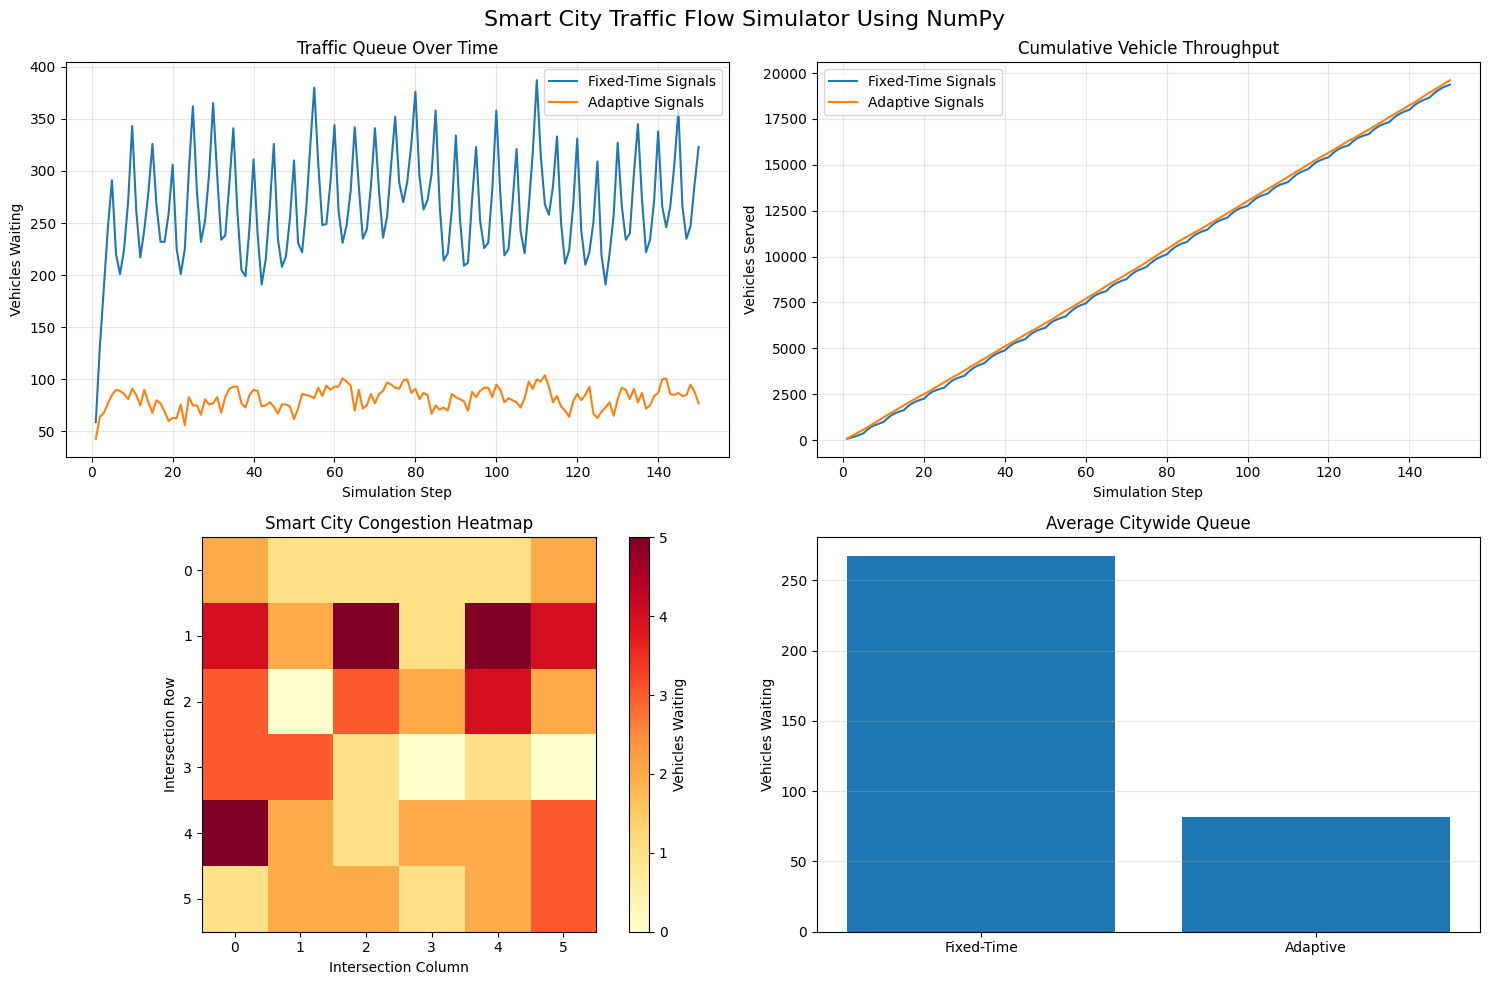

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

steps = np.arange(1, SIMULATION_STEPS + 1)


axes[0, 0].plot(
    steps, fixed_results["total_queue"],
    label="Fixed-Time Signals"
)
axes[0, 0].plot(
    steps, adaptive_results["total_queue"],
    label="Adaptive Signals"
)
axes[0, 0].set_title("Traffic Queue Over Time")
axes[0, 0].set_xlabel("Simulation Step")
axes[0, 0].set_ylabel("Vehicles Waiting")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)


axes[0, 1].plot(
    steps, fixed_results["throughput"],
    label="Fixed-Time Signals"
)
axes[0, 1].plot(
    steps, adaptive_results["throughput"],
    label="Adaptive Signals"
)
axes[0, 1].set_title("Cumulative Vehicle Throughput")
axes[0, 1].set_xlabel("Simulation Step")
axes[0, 1].set_ylabel("Vehicles Served")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)


final_density = adaptive_results["density"][-1]
im = axes[1, 0].imshow(final_density, cmap="YlOrRd")
axes[1, 0].set_title("Smart City Congestion Heatmap")
axes[1, 0].set_xlabel("Intersection Column")
axes[1, 0].set_ylabel("Intersection Row")
fig.colorbar(im, ax=axes[1, 0], label="Vehicles Waiting")


axes[1, 1].bar(
    ["Fixed-Time", "Adaptive"],
    [
        np.mean(fixed_results["total_queue"]),
        np.mean(adaptive_results["total_queue"])
    ]
)
axes[1, 1].set_title("Average Citywide Queue")
axes[1, 1].set_ylabel("Vehicles Waiting")
axes[1, 1].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Smart City Traffic Flow Simulator Using NumPy",
    fontsize=16
)
plt.tight_layout()
plt.show()


In [5]:
fixed_avg_queue = np.mean(fixed_results["total_queue"])
adaptive_avg_queue = np.mean(adaptive_results["total_queue"])

fixed_served = fixed_results["departures"]
adaptive_served = adaptive_results["departures"]

print("=" * 50)
print("       SMART CITY TRAFFIC REPORT")
print("=" * 50)

print(f"City size: {CITY_SIZE} x {CITY_SIZE} intersections")
print(f"Simulation duration: {SIMULATION_STEPS} steps")
print(f"Total vehicles arriving: {adaptive_results['arrivals']}")

print("\n--- Fixed-Time Traffic Signals ---")
print(f"Vehicles served: {fixed_served}")
print(f"Average total queue: {fixed_avg_queue:.2f}")

print("\n--- Adaptive Traffic Signals ---")
print(f"Vehicles served: {adaptive_served}")
print(f"Average total queue: {adaptive_avg_queue:.2f}")

if fixed_avg_queue > 0:
    improvement = (
        (fixed_avg_queue - adaptive_avg_queue)
        / fixed_avg_queue
    ) * 100

    print(f"\nChange in average queue: {improvement:.2f}%")

    if improvement > 0:
        print("Result: Adaptive control reduced the average queue.")
    elif improvement < 0:
        print("Result: Fixed-time control had the smaller average queue.")
    else:
        print("Result: Both strategies had the same average queue.")

print("\nProject completed successfully!")


       SMART CITY TRAFFIC REPORT
City size: 6 x 6 intersections
Simulation duration: 150 steps
Total vehicles arriving: 19686

--- Fixed-Time Traffic Signals ---
Vehicles served: 19363
Average total queue: 267.13

--- Adaptive Traffic Signals ---
Vehicles served: 19609
Average total queue: 81.76

Change in average queue: 69.39%
Result: Adaptive control reduced the average queue.

Project completed successfully!
